In [61]:
import os
os.chdir('/home/hrayrh/projects/incontext_spurious')
os.environ['DATA_ROOT_DIR'] = '/home/hrayrh/data'

In [62]:
import sys
sys.path.append('/home/hrayrh/projects/incontext_spurious')

In [63]:
from collections import Counter
from matplotlib import pyplot as plt
%matplotlib inline
import numpy as np
from sklearn.linear_model import LogisticRegression
from src.datamodules.datasets import Camelyon17Extracted

# Understanding WILDS Camelyon17 slides

Slides seem to be a source of easy generalization

In [95]:
from wilds.datasets.camelyon17_dataset import Camelyon17Dataset

In [96]:
cam17_ds = Camelyon17Dataset(root_dir='/home/hrayrh/data')

In [150]:
train_ds = cam17_ds.get_subset('train')
id_val_ds = cam17_ds.get_subset('id_val')
val_ds = cam17_ds.get_subset('val')
test_ds = cam17_ds.get_subset('test')

In [151]:
train_slides = train_ds.metadata_array[:, 1]
id_val_slides = id_val_ds.metadata_array[:, 1]
val_slides = val_ds.metadata_array[:, 1]
test_slides = test_ds.metadata_array[:, 1]

In [152]:
train_slides_unique = np.unique(train_slides.numpy())
train_slides_unique

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 30, 31, 32, 33, 34, 35, 36,
       37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49])

In [153]:
id_val_slides_unique = np.unique(id_val_slides.numpy())
id_val_slides_unique

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 30, 31, 32, 33, 34, 35, 36,
       37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49])

In [154]:
val_slides_unique = np.unique(val_slides.numpy())
val_slides_unique

array([10, 11, 12, 13, 14, 15, 16, 17, 18, 19])

In [155]:
test_slides_unique = np.unique(test_slides.numpy())
test_slides_unique

array([20, 21, 22, 23, 24, 25, 26, 27, 28, 29])

In [163]:
for slide in train_slides_unique:
    mask = train_ds.metadata_array[:, 1] == slide
    ys = train_ds.metadata_array[:, 2][mask]
    hospitals = train_ds.metadata_array[:, 0][mask]
    print(slide, Counter(ys.numpy()), Counter(hospitals.numpy()))

0 Counter({0: 3845, 1: 33}) Counter({0: 3878})
1 Counter({0: 3855, 1: 274}) Counter({0: 4129})
2 Counter({0: 2541, 1: 1056}) Counter({0: 3597})
3 Counter({1: 11345, 0: 883}) Counter({0: 12228})
4 Counter({1: 4415, 0: 2183}) Counter({0: 6598})
5 Counter({0: 1884, 1: 1065}) Counter({0: 2949})
6 Counter({0: 3079, 1: 5}) Counter({0: 3084})
7 Counter({0: 1423, 1: 7}) Counter({0: 1430})
8 Counter({1: 7851, 0: 4267}) Counter({0: 12118})
9 Counter({0: 2726, 1: 688}) Counter({0: 3414})
30 Counter({0: 9541, 1: 14}) Counter({3: 9555})
31 Counter({0: 3021, 1: 116}) Counter({3: 3137})
32 Counter({0: 6019, 1: 1944}) Counter({3: 7963})
33 Counter({0: 3598, 1: 17}) Counter({3: 3615})
34 Counter({0: 3397, 1: 151}) Counter({3: 3548})
35 Counter({0: 5308, 1: 166}) Counter({3: 5474})
36 Counter({0: 9598, 1: 13}) Counter({3: 9611})
37 Counter({0: 4746, 1: 57}) Counter({3: 4803})
38 Counter({1: 43312, 0: 8320}) Counter({3: 51632})
39 Counter({1: 12733, 0: 4888}) Counter({3: 17621})
40 Counter({0: 6487, 1: 1

In [161]:
len(train_slides) * 0.2 / 2

# 3, 

30243.600000000002

In [156]:
for slide in test_slides_unique:
    mask = test_ds.metadata_array[:, 1] == slide
    ys = test_ds.metadata_array[:, 2][mask]
    print(slide, Counter(ys.numpy()))

20 Counter({0: 3783, 1: 27})
21 Counter({0: 3684, 1: 10})
22 Counter({1: 4229, 0: 2981})
23 Counter({1: 2761, 0: 2527})
24 Counter({0: 7543, 1: 184})
25 Counter({0: 3305, 1: 1029})
26 Counter({0: 3320, 1: 495})
27 Counter({0: 4446, 1: 110})
28 Counter({1: 26998, 0: 4880})
29 Counter({1: 6684, 0: 6058})


In [160]:
len(test_slides) * 0.2 / 2
# test slides train_split = 20, 21, 22, 24, 25, 26, 27, 28
# test slides val split = 23, 29

8505.4

In [118]:
train_ds.metadata_fields

['hospital', 'slide', 'y', 'from_source_domain']

In [133]:
train_slide_0_indices = np.where(train_ds.metadata_array[:, 1] == 0)[0]
train_slide_1_indices = np.where(train_ds.metadata_array[:, 1] == 1)[0]

In [134]:
id_val_slide_0_indices = np.where(id_val_ds.metadata_array[:, 1] == 0)[0]
id_val_slide_1_indices = np.where(id_val_ds.metadata_array[:, 1] == 1)[0]

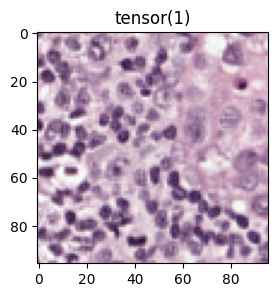

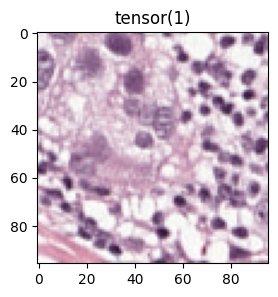

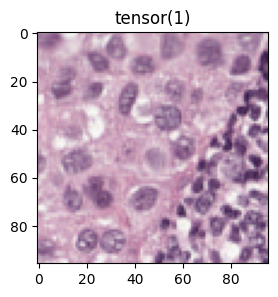

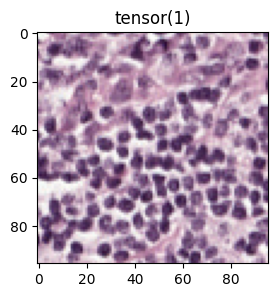

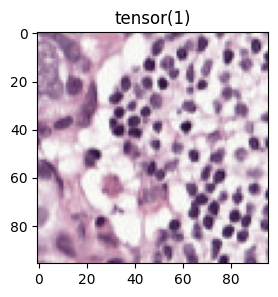

In [141]:
for idx in train_slide_1_indices[:5]:
    fig, ax = plt.subplots(figsize=(3, 3))
    ax.imshow(train_ds[idx][0])
    ax.set_title(train_ds[idx][1])
    plt.show()

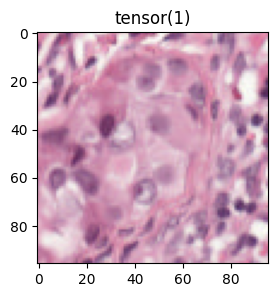

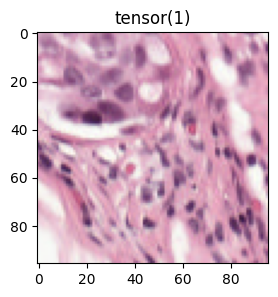

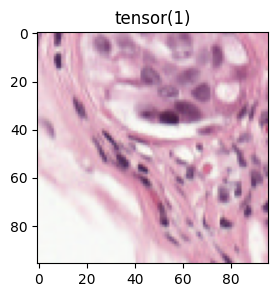

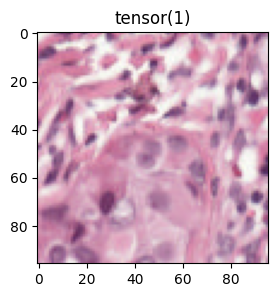

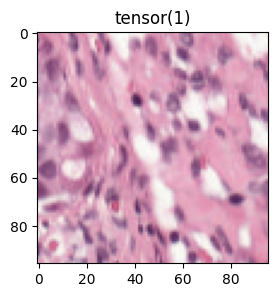

In [164]:
for idx in train_slide_0_indices[:5]:
    fig, ax = plt.subplots(figsize=(3, 3))
    ax.imshow(train_ds[idx][0])
    ax.set_title(train_ds[idx][1])
    plt.show()

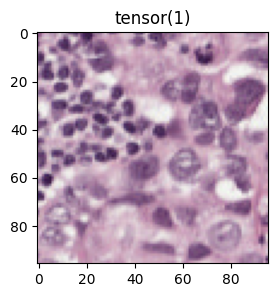

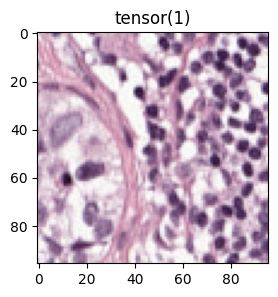

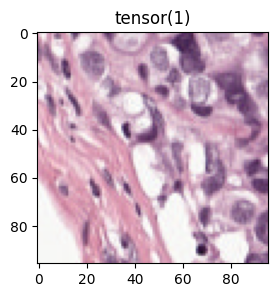

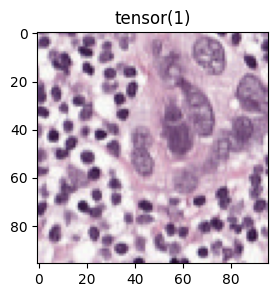

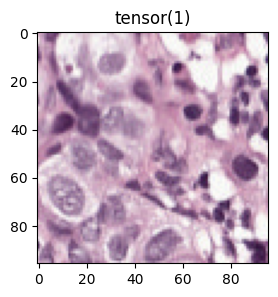

In [142]:
for idx in id_val_slide_1_indices[:5]:
    fig, ax = plt.subplots(figsize=(3, 3))
    ax.imshow(id_val_ds[idx][0])
    ax.set_title(id_val_ds[idx][1])
    plt.show()

# Inspecting Camelyon17Extracted to see how well Y and S are predictable from encodings

**Dino V2 ViTB14**
* Y acc = 97.84
* S acc = 99.98

**ResNet-50**
* Y acc = 97.62
* S acc = 99.90

**Scratch ResNet-18**
* Y acc = 89%
* S acc = 97%

In [4]:
ds = Camelyon17Extracted(
    root_dir='/home/hrayrh/data',
    # encoding_extractor='dinov2_vitb14',
    # encoding_extractor='resnet50',
    # encoding_extractor='resnet18',
    encoding_extractor='scratch_resnet18',
)

In [5]:
train = ds.get_subset('train')
val = ds.get_subset('val')
test = ds.get_subset('test')
print(f'{len(train)=}, {len(val)=}, {len(test)=}')

len(train)=173864, len(val)=43242, len(test)=88329


In [6]:
train_X, examples = train[np.arange(len(train))]
print(f'{train_X.shape=}, {examples.shape=}')
train_s = examples[:, 1]
train_y = examples[:, 2]
print(f'{train_s.shape=}, {train_y.shape=}')

train_X.shape=(173864, 512), examples.shape=(173864, 3)
train_s.shape=(173864,), train_y.shape=(173864,)


In [10]:
val_X, examples = val[np.arange(len(val))]
print(f'{val_X.shape=}, {examples.shape=}')
val_s = examples[:, 1]
val_y = examples[:, 2]
print(f'{val_s.shape=}, {val_y.shape=}')

val_X.shape=(43242, 512), examples.shape=(43242, 3)
val_s.shape=(43242,), val_y.shape=(43242,)


In [8]:
test_X, examples = test[np.arange(len(test))]
print(f'{test_X.shape=}, {examples.shape=}')
test_s = examples[:, 1]
test_y = examples[:, 2]
print(f'{test_s.shape=}, {test_y.shape=}')

test_X.shape=(88329, 512), examples.shape=(88329, 3)
test_s.shape=(88329,), test_y.shape=(88329,)


## Predicting Y

In [9]:
log_reg = LogisticRegression(max_iter=10000)
log_reg.fit(train_X, train_y)
val_pred = log_reg.predict(val_X)
val_acc = np.mean(val_pred == val_y)
print(f'predicting Y, {val_acc=}')

predicting Y, val_acc=0.8908006105175523


## Predicting S

In [10]:
log_reg = LogisticRegression(max_iter=10000)
log_reg.fit(train_X, train_s)
val_pred = log_reg.predict(val_X)
val_acc = np.mean(val_pred == val_s)
print(f'predicting S, {val_acc=}') 

predicting S, val_acc=0.9695203737107442


## Predicting Y and S but on test set

In [175]:
perm = np.random.permutation(len(test_X))
test_train_size = int(0.8 * len(test_X))
test_train_X = test_X[perm[:test_train_size]]
test_train_y = test_y[perm[:test_train_size]]
test_train_s = test_s[perm[:test_train_size]]
test_val_X = test_X[perm[test_train_size:]]
test_val_y = test_y[perm[test_train_size:]]
test_val_s = test_s[perm[test_train_size:]]

log_reg = LogisticRegression(max_iter=10000)
log_reg.fit(test_train_X, test_train_y)
test_val_pred = log_reg.predict(test_val_X)
test_val_acc = np.mean(test_val_pred == test_val_y)
print(f'predicting Y, {test_val_acc=}')

log_reg = LogisticRegression(max_iter=10000)
log_reg.fit(test_train_X, test_train_s)
test_val_pred = log_reg.predict(test_val_X)
test_val_acc = np.mean(test_val_pred == test_val_s)
print(f'predicting S, {test_val_acc=}')

predicting Y, test_val_acc=0.9437903317106305
predicting S, test_val_acc=0.9759990943054455


## Imbalanced contexts

In [ ]:
def worst_group_acc(pred, y, s):
    g = 2 * y + s
    accs = []
    for g_idx in range(4):
        mask = (g == g_idx)
        g_acc = np.mean(pred[mask] == y[mask])
        accs.append(g_acc)
    print('group accuracies:', accs)
    print('overall accuracy:', np.mean(pred==y))
    return np.min(accs)

In [59]:
train_X, examples = train[np.arange(len(train))]
print(f'{train_X.shape=}, {examples.shape=}')
train_s = examples[:, 1]
train_y = examples[:, 2]
maj_mask = (train_s == train_y)
min_mask = (train_s != train_y)
print('maj min exmaples before', np.sum(maj_mask), np.sum(min_mask))
min_ratio = 1.0 / 9  # produces [0.45, 0.05, 0.05, 0.45]
# min_ratio = 0.0  # produces [0.5, 0.0, 0.0, 0.5]
select_min_indices = np.random.choice(
    np.where(min_mask)[0], 
    size=int(np.sum(min_mask) * (1-min_ratio)),
    replace=False)
min_mask[select_min_indices] = False
print('maj min exmaples after', np.sum(maj_mask), np.sum(min_mask))
mask = (maj_mask | min_mask)

print(f'{train_s.shape=}, {train_y.shape=}')

# normal ERM
log_reg = LogisticRegression(max_iter=1000)    
log_reg.fit(train_X[mask], train_y[mask])

# downsampled ERM
if False:
    log_reg = LogisticRegression(max_iter=1000)    
    X = train_X[mask]
    y = train_y[mask]
    s = train_s[mask]
    g = 2 * y + s
    counts = Counter(g)
    print(counts)
    min_count = np.min([counts[g_idx] for g_idx in counts])
    selected_indices = []
    for g_idx in range(4):
        selected_indices.append(
            np.random.choice(np.where(g==g_idx)[0], size=min_count, replace=False)
        )
    selected_indices=np.concatenate(selected_indices, axis=0)
    log_reg.fit(X[selected_indices], y[selected_indices])

train_X.shape=(173864, 512), examples.shape=(173864, 3)
maj min exmaples before 86756 87108
maj min exmaples after 86756 9679
train_s.shape=(173864,), train_y.shape=(173864,)


In [60]:
val_pred = log_reg.predict(val_X)
print(f'predicting Y, matching Y, wg acc: {worst_group_acc(val_pred, val_y, val_s)}')

group accuracies: [0.974212252994583, 0.6192567968657248, 0.6690033526363913, 0.9523754075454122]
overall accuracy: 0.8081032329679478
predicting Y, matching Y, wg acc: 0.6192567968657248


In [54]:
val_pred = log_reg.predict(val_X)
print(f'predicting Y, matching S, wg acc: {worst_group_acc(val_pred, val_s, val_y)}')

group accuracies: [0.9761196307316701, 0.34585492227979275, 0.3863231627686098, 0.9531904983698184]
overall accuracy: 0.6653947550992091
predicting Y, matching S, wg acc: 0.34585492227979275


# Inspecting Camelyon17EmbContextsDatasetV2 to make sure it builds correct ICL instances

In [90]:
from src.datamodules.datasets import Camelyon17EmbContextsDatasetV2

In [91]:
icl_ds = Camelyon17EmbContextsDatasetV2(
    root_dir='/home/hrayrh/data',
    encoding_extractor='dinov2_vitb14',
    data_length=1000000,
    context_split='train',
    query_split='val',
    context_class_size=64,
    context_group_proportions=[0.45, 0.05, 0.05, 0.45],
    query_group_proportions=[0.45, 0.05, 0.05, 0.45],
    spurious_setting='wb_erm',
    sp_token_generation_mode='opposite',
    use_context_as_intermediate_queries=True,  # naive
    permute_input_dim=False
)

In [92]:
input_seq, context, queries, query_indices = icl_ds[2]

In [93]:
print(f"""
    {input_seq.shape=},
    {context.shape=},
    {queries.shape=},
    {query_indices.shape=},
""")


    input_seq.shape=(384, 768),
    context.shape=(128, 3),
    queries.shape=(128, 3),
    query_indices.shape=(128,),



In [94]:
context_groups = 2 * context[:, 1] + context[:, 2]
print(Counter(context_groups))
print(58/6, 9)

Counter({0: 58, 3: 58, 1: 6, 2: 6})
9.666666666666666 9


In [95]:
query_groups = 2 * queries[:, 1] + queries[:, 2]
print(Counter(query_groups))

Counter({3: 59, 0: 57, 1: 6, 2: 6})


In [96]:
np.mean(context[:, 1] == context[:, 2])

0.90625

In [97]:
np.mean(queries[:, 1] == queries[:, 2])

0.90625

In [100]:
tmp = []
for idx in range(2000):
    _, _, queries, query_indices = icl_ds[idx]
    tmp.append(queries[-2][1:])

In [101]:
tmp = np.array(tmp)
tmp = 2*tmp[:, 0]+tmp[:,1]
Counter(tmp)

Counter({0: 927, 3: 889, 2: 97, 1: 87})